# Monte Carlo Example Using Cahoy Models 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rc
from astropy import units as u
from synphot import SourceSpectrum
from synphot.models import Empirical1D
from synphot import SpectralElement
from synphot import Observation
import scipy.stats as stats


plt.style.use('default')
rc('xtick', labelsize=15)
rc('ytick', labelsize=15)
rc('axes', labelsize=20)
rc('legend', fontsize=15) 
rc('text', usetex=True)
rc('text.latex', preamble=r'\usepackage{wasysym}\usepackage{siunitx}')
%config InlineBackend.figure_format = "retina"

#### Defining functions that convert planet-star flux ratios to planetary radii given $A_{\rm g}\Phi$, and vice versa
Using the following equation:

$\frac{F_{\rm p}}{F_{\rm s}} = A_{\rm g} \Phi(\alpha)\left( \frac{R_{\rm p}}{d} \right)^{\!2} $

where $R_{\rm p}$ is the radius of the planet, $d$ is the distance between the planet and the star at the time of observation, $A_{\rm g}$ is the geometric albedo, and $\Phi(\alpha)$ is the planetary phase function dependent on the phase angle $\alpha$ (i.e., the star-planet-observer angle).

In [2]:
def rp(au, flux_contrast, agphi):
    """
    Planet radius from reflected-light planet-star flux contrast, planet-star separation, and AgPhi.

    Parameters
    ----------
    au : float or array-like
        Semi-major axis (orbital distance) in AU.
    flux_contrast : float or array-like
        Planet-to-star flux ratio, fp/fs (dimensionless).
    agphi : float or array-like
        The geometric albedo multiplied by the phase function, AgPhi
        (dimensionless).

    Returns
    -------
    Rp_earthunits : float or numpy.ndarray
        Planet radius in Earth radii.
    """
    
    au = au*u.AU.to(u.km) 
    Rp = au * np.sqrt(flux_contrast / agphi)
    Rp_earthunits = Rp*u.km.to(u.Rearth)
    return Rp_earthunits

def flux_from_AgPhi(radius_rade, au, agphi):
    """
    Planet-star flux contrast from planet radius, planet-star separation, and AgPhi.

    Parameters
    ----------
    Rp_earthunits : float or array-like
        Planet radius in Earth radii.
    au : float or array-like
        Semi-major axis (orbital distance) in AU.
    agphi : float or array-like
        The geometric albedo multiplied by the phase function, AgPhi
        (dimensionless).

    Returns
    -------
    flux_contrast : float or array-like
        Planet-to-star flux ratio, fp/fs (dimensionless).
    """
    radius_km = radius_rade*u.R_earth.to(u.km)
    a = au*u.AU.to(u.km) # AU 
    flux_constrast = agphi * (radius_km/a)**2
    return flux_constrast

#### Loading table that contains phase-dependent lognormal prior for $A_{\rm g}\Phi$ 

The prior is a lognormal fitted to the log of the solar system $A_{\rm g}\Phi$ values (excluding Mercury) at each specified phase angle.

In [3]:
df_prior = pd.read_csv('agphi_prior_suissa.dat', sep=r'\s+', skiprows=9)
df_prior

,Phase_angle,mean,sigma
0,0.0,-1.00668,0.49450
1,1.0,-1.00795,0.49344
2,2.0,-1.01277,0.49461
3,3.0,-1.01840,0.49512
4,4.0,-1.02425,0.49492
...,...,...,...
176,176.0,-5.98583,3.61418
177,177.0,-6.38506,4.33729
178,178.0,-6.94815,5.39908
179,179.0,-7.02348,5.41703


#### Creating Monte Carlo routine to obtain inferred radius distribution

- This assumes an observation where the orbit of the planet is constrained. We assume a phase angle $\alpha$ and a planet-star separation (in AU) with fractional errors. We also assume a planet-star flux ratio with fractional error. 

- Each instance randomly draws a planet-to-star flux ratio from a Gaussian alongside random draws from Gaussians for both the phase angle and planet-star separation (using fractional errors that represent uncertainty in orbit measurements).

- Each instance uses the randomized draw for phase angle to obtain mean and sigma of lognormal $A_{\rm g}\Phi$ prior from above dataset. Then uses lognormal distribution to randomly draw $A_{\rm g}\Phi$ value.

- Each instance calculates an inferred planetary radius using the randomly drawn planet-star flux ratio value, planet-star separation value, and $A_{\rm g}\Phi$ value 

In [4]:
def montecarlo(flux, alpha, au, flux_error, alpha_error, au_error): 
    """
    Monte Carlo propagation of uncertainties to a planet radius estimate.

    Draws the flux, orbital distance, and phase angle from their uncertainty
    distributions, draws AgPhi from a phase-angle-dependent lognormal prior,
    and computes the radius for each run.

    Parameters
    ----------
    flux : float
        Measured (nominal) flux. Must be positive.
    alpha : float
        Nominal phase angle in degrees. Must be from 0 to 180 degrees.
    au : float
        Nominal orbital distance in AU. Must be positive.
    flux_error : float
        Fractional (1-sigma) uncertainty on the flux, e.g. 0.1 for 10%.
        Must be non-negative.
    alpha_error : float
        Fractional (1-sigma) uncertainty on the phase angle. Must be
        non-negative.
    au_error : float
        Fractional (1-sigma) uncertainty on the orbital distance. Must be
        non-negative.

    Returns
    -------
    radius_guesses : numpy.ndarray
        Radius estimate from each of the 100,000 Monte Carlo runs, in the units
        of Earth radii.
    """
        
    assert flux > 0, f"flux_integrated must be positive, got {flux}"
    assert au > 0, f"au must be positive, got {au}"
    assert flux_error >= 0 and au_error >= 0 and alpha_error >= 0, "flux_error, au_error, and alpha_error must be non-negative"
    
    flux_sigma = flux * flux_error 
    au_sigma = au * au_error 
    alpha_sigma = alpha * alpha_error 
    
    runs = 100000

    radius_guesses = np.empty(runs)
    agphi_randoms = np.empty(runs)
    flux_randoms = np.empty(runs)
    au_randoms = np.empty(runs)
    alpha_randoms = np.empty(runs)

    # first, find random alphas from truncated normal
    if alpha_error == 0: 
        alpha_randoms = np.full(runs, alpha, dtype=float)
    else:
        alpha_randoms = stats.truncnorm((0 - alpha) / alpha_sigma, (180 - alpha) / alpha_sigma, 
                                           loc=alpha, scale=alpha_sigma).rvs(runs)

    for i in range(runs):
        # find lognormal distribution of agphi from random alphas 
        AgPhi_mean = np.interp(x=alpha_randoms[i], xp=df_prior['Phase_angle'], fp=df_prior['mean'])
        AgPhi_sigma = np.interp(x=alpha_randoms[i], xp=df_prior['Phase_angle'], fp=df_prior['sigma'])
        # draw random agphi using lognormal distribution 
        agphi_random = np.random.lognormal(AgPhi_mean, AgPhi_sigma)
        agphi_randoms[i] = agphi_random

        # find random flux 
        flux_random = np.random.normal(flux, flux_sigma)
        while flux_random < 0:
            flux_random = np.random.normal(flux, flux_sigma)
        flux_randoms[i] = flux_random
        
        # find random au 
        au_random = np.random.normal(au, au_sigma)
        while au_random < 0: 
            au_random = np.random.normal(au, au_sigma) 
        au_randoms[i] = au_random 

        radius_guesses[i] = rp(au_random, flux_random, agphi_random)

    return radius_guesses

#### Example Using Synthetic Reflected Light Spectra of Jupiters and Neptunes from [Cahoy et al. 2010](https://ui.adsabs.harvard.edu/abs/2010ApJ...724..189C)

These are albedo spectra of modelled Jupiters and Neptunes range of planet-star separations, cloud species, metallicities, and observed phase angles. We choose $\alpha = 90^\circ$, and Jupiter and Neptune metallicity of 3x and 30x, respectively. 

We iterate over the following planet-star separations: 0.8 AU, 2 AU, 5 AU, and 10 AU. The models at 0.8 AU are cloud-free. The models at 2 AU are water cloud-dominated, and the models at 5 and 10 AU are ammonia and water cloud-dominated. 


##### First we convert the albedo spectra to reflectance spectra in units of planet-star flux ratios

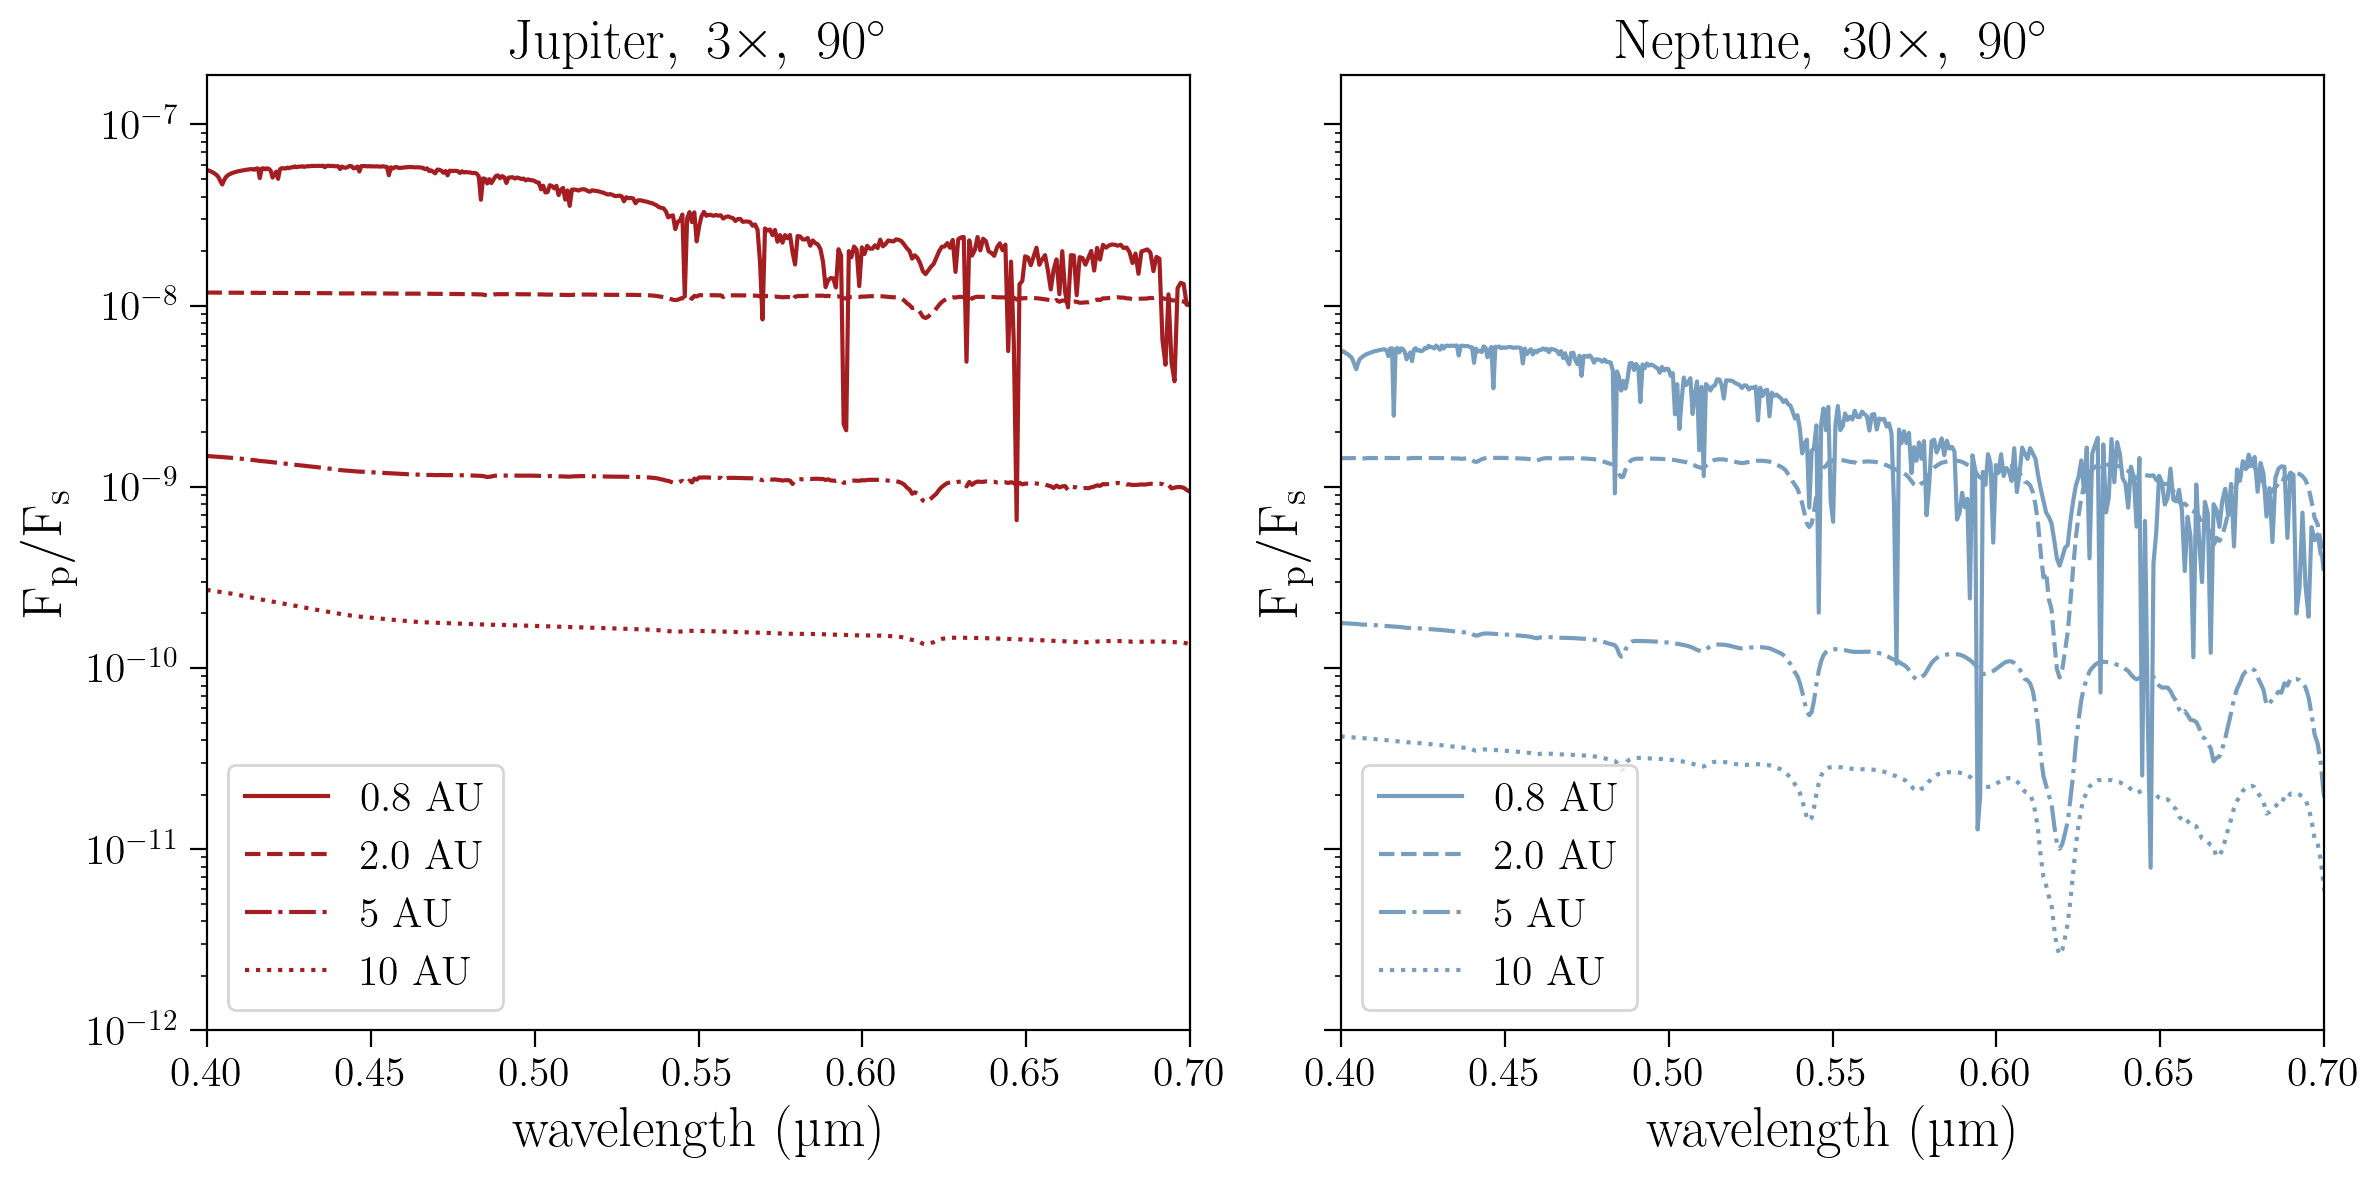

In [5]:
# loading spectra 
cahoy_folder = 'cahoy_et_al_2010_models/'
au = [0.8, 2.0, 5, 10] 
jupiter_metallicity = 3 
neptune_metallicity = 30 

jupiter_radius = 1*u.R_jup.to(u.R_earth)
neptune_radius = 24764*u.km.to(u.R_earth)

jupiter_color = '#a41d21'
neptune_color = '#779ebf'

fig, ax = plt.subplots(1, 2, figsize=(12,6), sharey=True)
for i in au: 
    
    if i == 0.8: 
        ls = 'solid'
    elif i == 2.0: 
        ls = 'dashed' 
    elif i == 5: 
        ls = 'dashdot'
    else: 
        ls = 'dotted'
    
    label = r'\textrm{' + f'{i} AU' + '}'

    # first the jupiters 
    subfolder = str(i)+'au '+str(jupiter_metallicity)+'x albedos'
    filename = '/00_Spectral_Albedos   1.57080.txt'
    df = pd.read_csv(cahoy_folder+subfolder+filename, sep=r'\s+', skiprows=4)
    df.columns = ['K', 'WAVELN', 'NEFF', 'GEOM-ALB', 'BOND/QFIT', 'BOND/GEOM', 'Q-FITTED']
    geometric_albedo = df['GEOM-ALB']
    wavelength = df['WAVELN']
    flux_ratios = flux_from_AgPhi(jupiter_radius, i, geometric_albedo)
    ax[0].plot(wavelength, flux_ratios, color=jupiter_color, ls=ls, label=label)
    ax[0].set_xlim(0.4,0.7)

    # next the neptunes  
    subfolder = str(i)+'au '+str(neptune_metallicity)+'x albedos'
    filename = '/00_Spectral_Albedos   1.57080.txt'
    df = pd.read_csv(cahoy_folder+subfolder+filename, sep=r'\s+', skiprows=4)
    df.columns = ['K', 'WAVELN', 'NEFF', 'GEOM-ALB', 'BOND/QFIT', 'BOND/GEOM', 'Q-FITTED']
    geometric_albedo = df['GEOM-ALB']
    wavelength = df['WAVELN']
    flux_ratios = flux_from_AgPhi(neptune_radius, i, geometric_albedo)
    ax[1].plot(wavelength, flux_ratios, color=neptune_color, ls=ls, label=label)


ax[0].set_xlabel(r'\textrm{wavelength (\si{\micro\metre})}')
ax[0].set_ylabel(r'$\rm{F_p/F_s}$')
ax[0].set_yscale('log')
ax[0].set_xlim(0.4,0.7)
ax[0].set_ylim(1e-11,)
ax[0].tick_params(axis='x', which='both', direction='out', length=6)
ax[0].tick_params(axis='y', direction='out', length=6)
ax[0].set_title(r'$\rm{Jupiter,~3\times,~90^{\circ}}$', size=20)
ax[0].legend(loc='lower left')

ax[1].set_xlabel(r'\textrm{wavelength (\si{\micro\metre})}')
ax[1].set_ylabel(r'$\rm{F_p/F_s}$')
ax[1].set_yscale('log')
ax[1].set_xlim(0.4,0.7)
ax[1].set_ylim(1e-12,)
ax[1].tick_params(axis='x', which='both', direction='out', length=6)
ax[1].tick_params(axis='y', direction='out', length=6)
ax[1].set_title(r'$\rm{Neptune,~30\times,~90^{\circ}}$', size=20)
ax[1].legend(loc='lower left')
plt.tight_layout()
fig.subplots_adjust(hspace=0.3)

##### We create a function that can integrate reflectance spectrum over V band 

In [6]:
def obs(wave, flux):
    """
    Integrated over V-band planet-to-star flux ratio from a reflectance spectrum in units of planet-star flux ratios.

    Takes input reflectance spectrum, multiplies it by the solar spectrum to get planet's flux, 
    observes both the planet and the star through the Johnson V filter. 
    Returns the ratio of their effective stimuli.

    Parameters
    ----------
    wave : array-like
        Wavelengths of the spectrum, in microns.
    flux : array-like
        Planet-to-star flux ratio at each wavelength (dimensionless). 

    Returns
    -------
    float
        Planet-star flux ratio integrated over V band (dimensionless).
    """
    
    # set Fp/Fs spectrum 
    sorted_wave, sorted_flux = zip(*sorted(zip(wave, flux)))
    constrast_flux = SpectralElement(Empirical1D, points=sorted_wave*u.micron, lookup_table=sorted_flux, keep_neg=True)

    # define flux of star (Solar in case of Cahoy et al. 2010 models)
    sun_file = 'https://archive.stsci.edu/hlsps/reference-atlases/cdbs/calspec/sun_reference_stis_002.fits'
    flux_star = SourceSpectrum.from_file(sun_file)
    
    # define flux of planet using contrast ratio 
    flux_planet = flux_star * constrast_flux

    # observing both planet and star through V band 
    v = SpectralElement.from_filter('johnson_v')
    obs_planet = Observation(flux_planet, v, force='taper')
    obs_star   = Observation(flux_star, v, force='taper')

    effstim_planet = obs_planet.effstim(flux_unit='flam')
    effstim_star   = obs_star.effstim(flux_unit='flam')

    Fp_over_Fs_V = (effstim_planet / effstim_star).value # dimensionless, contrast ratio 

    return Fp_over_Fs_V


##### For each spectrum, we simulate a V band observation and use that as planet-star flux ratio for our Monte Carlo routine. We assume $\alpha = 90^\circ$. We assume fractional errors on the planet-star flux, phase angle, and planet-star separation to be 10%. 

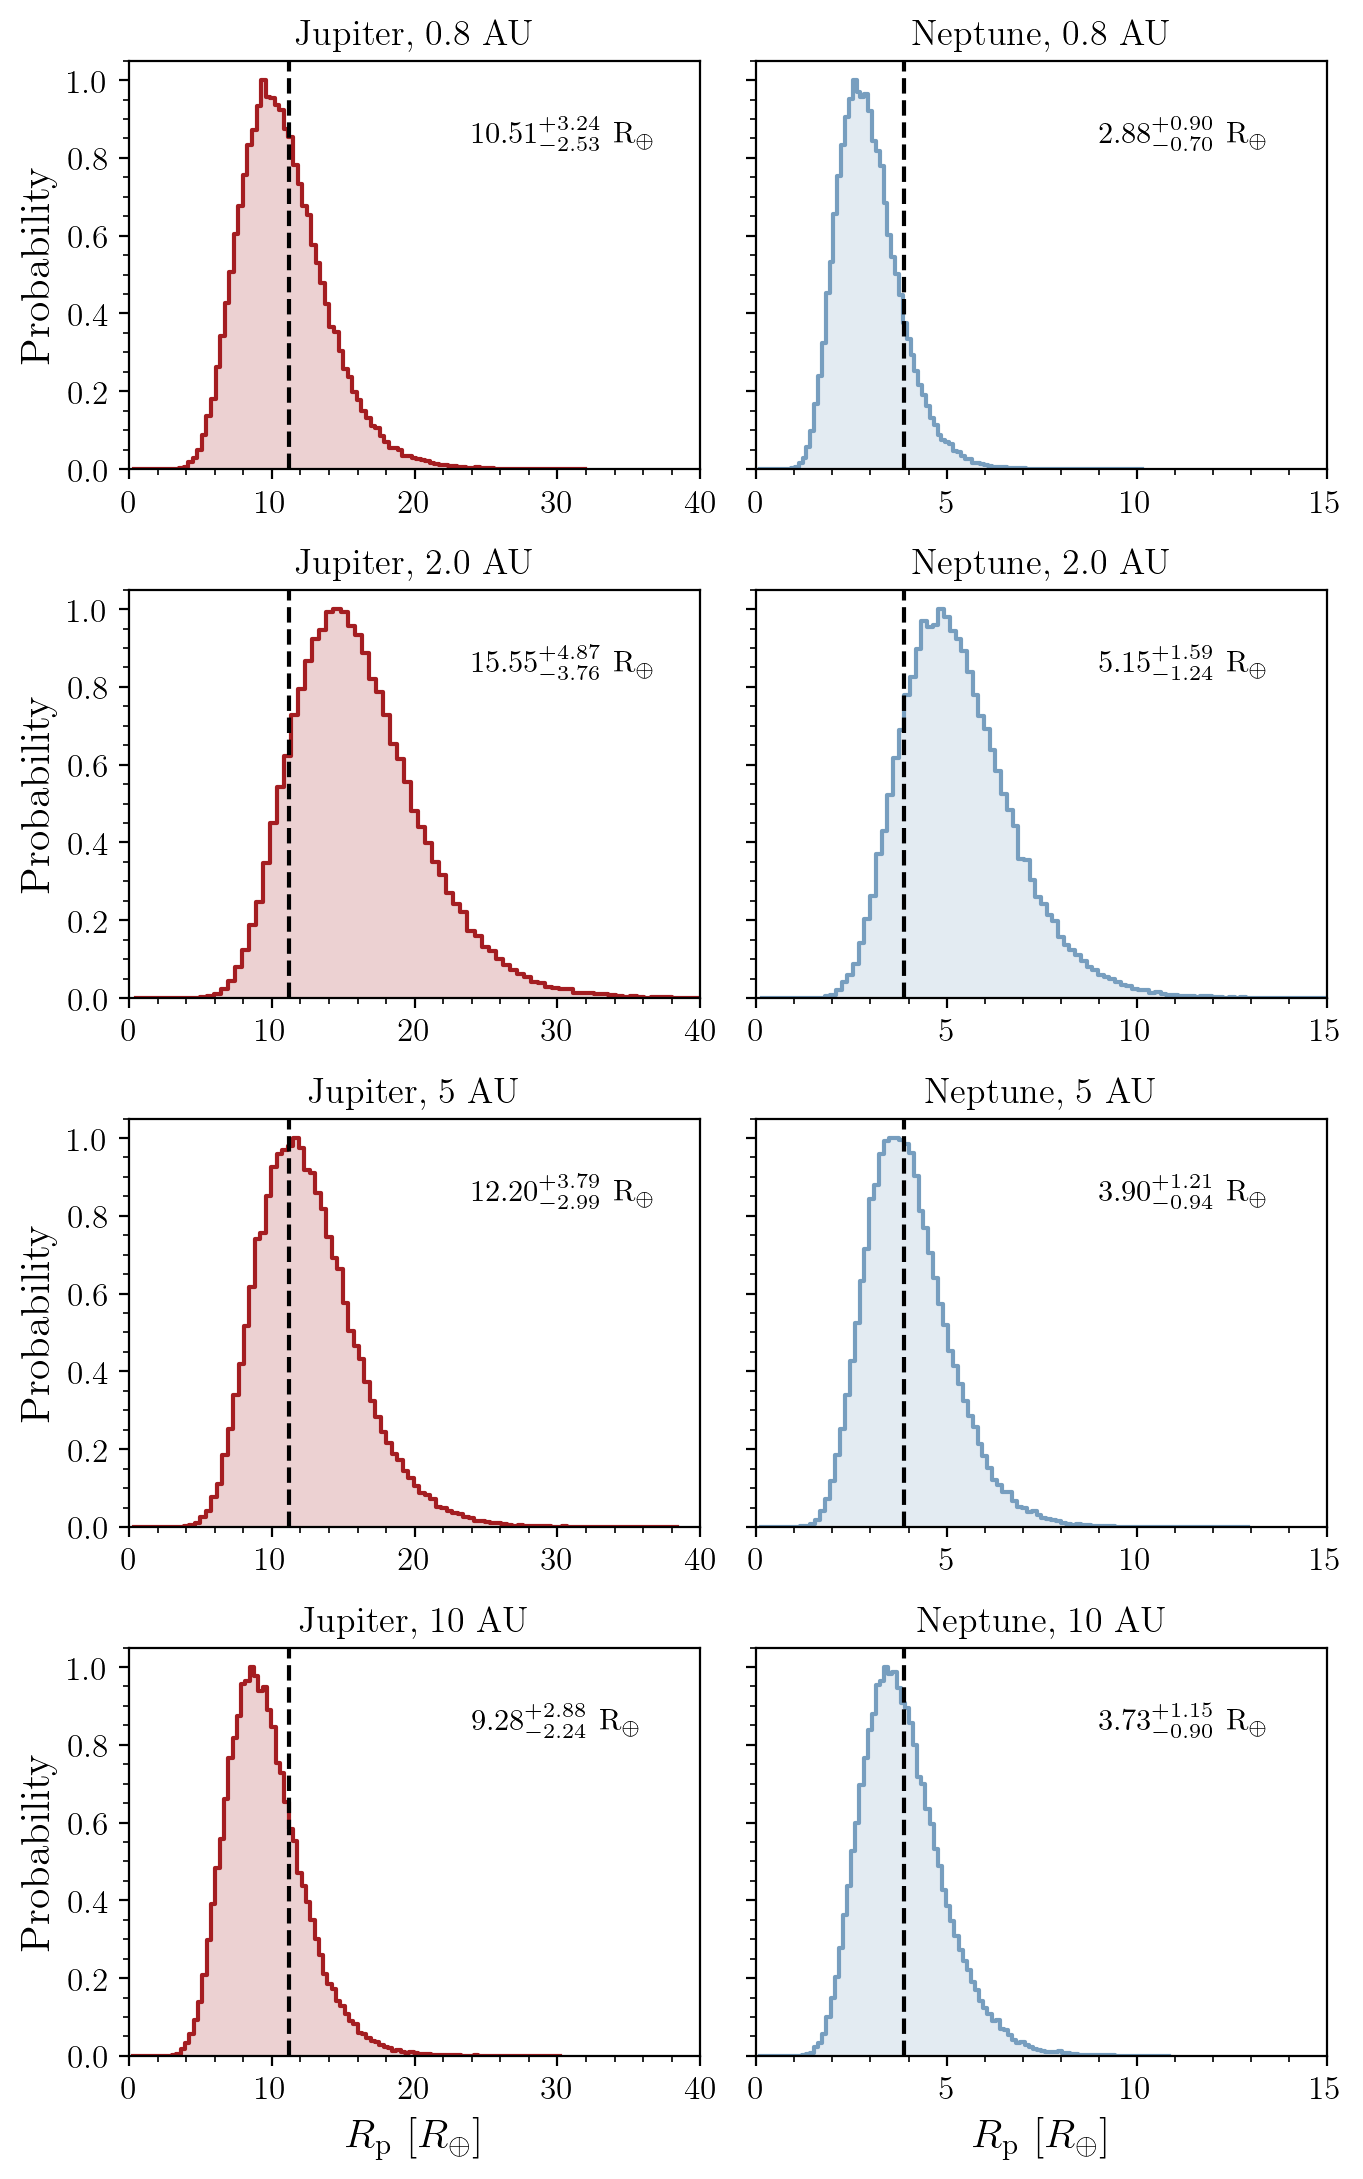

In [8]:
# loading example albedo spectra of Jupiters and Neptunes 
# Planet-star separation: 0.8 AU, 2 AU, 5 AU, 10 AU
# Jupiter-mass planets with 1x and 3x metallicity
# Neptune-mass planets with 10x and 30x metallicity 
cahoy_folder = 'cahoy_et_al_2010_models/'

alpha = 90
au = [0.8, 2.0, 5, 10]
jupiter_metallicity = 3
neptune_metallicity = 30 

jupiter_radius = 1*u.R_jup.to(u.R_earth)
neptune_radius = 24764*u.km.to(u.R_earth)

jupiter_color = '#a41d21'
neptune_color = '#779ebf'

fig, ax = plt.subplots(4, 2, figsize=(7,11), sharey=True, sharex=False)

for i, x in enumerate(au):
    # reading example albedo spectra 
    # first we'll do the jupiters 
    subfolder = str(x)+'au '+str(jupiter_metallicity)+'x albedos'
    filename = '/00_Spectral_Albedos   1.57080.txt'

    df = pd.read_csv(cahoy_folder+subfolder+filename, sep=r'\s+', skiprows=4)
    df.columns = ['K', 'WAVELN', 'NEFF', 'GEOM-ALB', 'BOND/QFIT', 'BOND/GEOM', 'Q-FITTED']
    albedo = df['GEOM-ALB']
    wavelength = df['WAVELN']

    # converting albedo spectra into planet-star flux ratios 
    flux_ratios = flux_from_AgPhi(jupiter_radius, x, albedo)

    # simulating V band observation
    flux = obs(wavelength, flux_ratios)

    # implementing MC routine to get inferred radius distribution 
    # assuming 10% errors on alpha, flux, and planet-star distance 
    radius_guesses = montecarlo(flux, alpha, au=x, flux_error=0.1, alpha_error=0.1, au_error=0.1)

    # plotting radius distribution for jupiters 
    handles = []
    num_bin = 100
    bin_lims = np.linspace(0,max(radius_guesses),num_bin+1)
    bin_centers = 0.5*(bin_lims[:-1]+bin_lims[1:])
    bin_widths = bin_lims[1:]-bin_lims[:-1]

    hist, _ = np.histogram(radius_guesses, bins=bin_lims)
    hist_norm = hist/np.max(hist)
    ax[i,0].step(bin_lims[1:], hist_norm, color=jupiter_color)
    ax[i,0].bar(bin_centers, hist_norm, width = bin_widths, align = 'center', alpha=0.2, color=jupiter_color)

    median = np.median(radius_guesses)
    lower_one_sigma = np.percentile(radius_guesses, 100-84.135)
    upper_one_sigma = np.percentile(radius_guesses, 84.135)
    label = rf"${median:.2f}^{{+{upper_one_sigma-median:.2f}}}_{{-{median-lower_one_sigma:.2f}}}\ \rm{{R}}_\oplus$"
    
    ax[i,0].axvline(jupiter_radius, color='k', ls='dashed')
    ax[i,0].set_title(r'\textrm{Jupiter, ' + f'{x}' + r'~AU'+'}', size=13)    
    ax[i,0].annotate(label, xy=(0.6,0.8), xycoords='axes fraction', fontsize=11)
    ax[i,0].minorticks_on()
    ax[i,0].tick_params(axis='both', labelsize=12)
    ax[i,0].set_xlim(0,40)
    ax[i,0].set_ylabel(r'$\textrm{Probability}$', fontsize=15)

    # now we do the neptunes 
    subfolder = str(x)+'au '+str(neptune_metallicity)+'x albedos'
    filename = '/00_Spectral_Albedos   1.57080.txt'

    df = pd.read_csv(cahoy_folder+subfolder+filename, sep=r'\s+', skiprows=4)
    df.columns = ['K', 'WAVELN', 'NEFF', 'GEOM-ALB', 'BOND/QFIT', 'BOND/GEOM', 'Q-FITTED']
    albedo = df['GEOM-ALB']
    wavelength = df['WAVELN']

    # converting albedo spectra into planet-star flux ratios 
    flux_ratios = flux_from_AgPhi(neptune_radius, x, albedo)

    # simulating V band observation
    flux = obs(wavelength, flux_ratios)
    
    # implementing MC routine to get inferred radius distribution 
    # assuming 10% errors on alpha, flux, and planet-star distance 
    radius_guesses = montecarlo(flux, alpha, au=x, flux_error=0.1, alpha_error=0.1, au_error=0.1)

    handles = []    
    num_bin = 100
    bin_lims = np.linspace(0,max(radius_guesses),num_bin+1)
    bin_centers = 0.5*(bin_lims[:-1]+bin_lims[1:])
    bin_widths = bin_lims[1:]-bin_lims[:-1]

    hist, _ = np.histogram(radius_guesses, bins=bin_lims)
    hist_norm = hist/np.max(hist)
    ax[i,1].step(bin_lims[1:], hist_norm, color=neptune_color)
    ax[i,1].bar(bin_centers, hist_norm, width = bin_widths, align = 'center', alpha=0.2, color=neptune_color)

    median = np.median(radius_guesses)
    lower_one_sigma = np.percentile(radius_guesses, 100-84.135)
    upper_one_sigma = np.percentile(radius_guesses, 84.135)
    label = rf"${median:.2f}^{{+{upper_one_sigma-median:.2f}}}_{{-{median-lower_one_sigma:.2f}}}\ \rm{{R}}_\oplus$"

    ax[i,1].axvline(neptune_radius, color='k', ls='dashed')
    ax[i,1].set_title(r'\textrm{Neptune, ' + f'{x}' + r'~AU'+'}', size=13)
    ax[i,1].annotate(label, xy=(0.6,0.8), xycoords='axes fraction', fontsize=11)
    ax[i,1].minorticks_on()
    ax[i,1].tick_params(axis='both', labelsize=12)
    ax[i,1].set_xlim(0,15)

ax[i,0].set_xlabel(r'$R\rm{_p}$ $[R_\oplus]$', fontsize=15)
ax[i,1].set_xlabel(r'$R\rm{_p}$ $[R_\oplus]$', fontsize=15)


plt.tight_layout() 
